# Did long-lived mammals evolve a "better" CIRBP?
Part 2 of the sleep-CIRBP project. The bowhead whale (200+ years) makes far more CIRBP, a cold-inducible DNA-repair protein, and its CIRBP gene uses more efficient codons (Firsanov et al., *Nature* 2025). This notebook asks whether that pattern holds **across mammals**.

| Test | Question |
|---|---|
| A. Codon efficiency | Do longer-lived mammals (for their body size) have more efficient CIRBP codons (CAI)? |
| B. Arginine codons | CIRBP's repair function needs its arginine-rich RGG region. Do long-lived species avoid the mutation-prone CGA/CGG arginine codons there? |
| C. Body temperature | Do cooler-bodied mammals differ? |
| D. Is it CIRBP-specific? | The same tests on ~45 control genes. CIRBP only counts if it beats most of them. |
| E. Protein AI | ESM-2 (protein language model) and the AlphaFold structure: which CIRBP positions differ between long- and short-lived species? |

Run: **Runtime → Run all** (about 15–25 min). Copy the **SEND THIS TO CLAUDE** box at the end.

In [1]:
!pip -q install biopython statsmodels fair-esm 2>/dev/null | grep -v -i dependency || true
import os, io, re, json, time, zipfile, warnings, requests, itertools
import numpy as np, pandas as pd
from scipy import stats
warnings.filterwarnings('ignore'); import logging; os.makedirs('data', exist_ok=True)
REPORT = []
def note(s): print(s); REPORT.append(str(s))

TARGET = ['CIRBP', 'RBM3']
# reference set for codon adaptation: highly expressed genes in every mammal
REF = ['RPL3','RPL4','RPL5','RPL7','RPL8','RPL10','RPL11','RPL13','RPL18','RPL23',
       'RPS2','RPS3','RPS4X','RPS6','RPS8','RPS11','RPS14','RPS19','EEF1A1','EEF2','GAPDH','ACTB']
# control genes: other RNA-binding proteins + general housekeeping genes
CONTROL = ['HNRNPA1','HNRNPA2B1','HNRNPK','SRSF1','SRSF3','SRSF7','PABPC1','ELAVL1','YBX1','TARDBP',
           'FUS','G3BP1','KHDRBS1','PTBP1','SFPQ','NONO','HNRNPU','CSDE1','SYNCRIP','RBMX',
           'PSMA1','PSMB1','POLR2A','CCT2','HSPA8','HSP90AB1','PPIA','LDHA','PGK1','ALDOA',
           'TPI1','ENO1','UBC','TUBB','VCP','SNRPB','NPM1','NCL','EIF4A1','EIF3A',
           'PCNA','XRCC5','XRCC6','PARP1','RAD51']
note(f'genes: {len(TARGET)} target, {len(REF)} reference, {len(CONTROL)} control')

genes: 2 target, 22 reference, 45 control


## 1. Download coding sequences of every mammal (Ensembl)
One-to-one orthologs of each human gene, across all mammals in Ensembl (taxon 40674). Cached to `data/` so a re-run is fast.

In [2]:
SERVER = 'https://rest.ensembl.org'
REF = REF[:14]; CONTROL = CONTROL[:25]          # fewer genes = much faster

def _get(url, tries=3):
    for i in range(tries):
        try:
            r = requests.get(url, headers={'Content-Type': 'application/json'}, timeout=45)
            if r.status_code == 429: time.sleep(5); continue
            r.raise_for_status(); return r.json()['data'][0]['homologies']
        except Exception as e:
            print('  retry', url.split('/')[-1][:20], i + 1, str(e)[:60]); time.sleep(5)
    return None

def fetch_orthologs(sym):
    # target/control genes: one-to-one orthologs only (cache from the earlier run is reused)
    fn = f'data/orth_{sym}.json'
    if os.path.exists(fn): return json.load(open(fn))
    hom = _get(f'{SERVER}/homology/symbol/human/{sym}?type=orthologues;sequence=cds;aligned=0;target_taxon=40674')
    if hom is None: print('  SKIPPED', sym); return {}
    out = {}
    for h in hom:
        if h.get('type') != 'ortholog_one2one': continue
        t = h['target']; out[t['species']] = (t.get('seq') or t.get('align_seq', '')).replace('-', '')
    if hom:
        s0 = hom[0]['source']; out['homo_sapiens'] = (s0.get('seq') or s0.get('align_seq', '')).replace('-', '')
    json.dump(out, open(fn, 'w')); return out

def fetch_ref(sym):
    # reference (ribosomal) genes have many copies, so Ensembl often calls them one-to-many.
    # Accept every ortholog type and keep the copy most similar to human for each species.
    fn = f'data/ref_{sym}.json'
    if os.path.exists(fn): return json.load(open(fn))
    hom = _get(f'{SERVER}/homology/symbol/human/{sym}?type=orthologues;sequence=cds;aligned=0;target_taxon=40674')
    if hom is None: print('  SKIPPED', sym); return {}
    best = {}
    for h in hom:
        t = h['target']; s = (t.get('seq') or t.get('align_seq', '')).replace('-', '')
        pid = t.get('perc_id', 0) or 0
        if s and (t['species'] not in best or pid > best[t['species']][0]): best[t['species']] = (pid, s)
    out = {k: v[1] for k, v in best.items()}
    json.dump(out, open(fn, 'w')); return out

SEQ = {}
for g in TARGET + CONTROL: SEQ[g] = fetch_orthologs(g)
for g in REF: SEQ[g] = fetch_ref(g)
FAILED = [g for g, v in SEQ.items() if not v]
note(f'downloaded {len(SEQ) - len(FAILED)} genes; skipped: {FAILED}')

# Some species' Ensembl CIRBP/RBM3 is a LONGER isoform (e.g. human 297 aa instead of 172 aa).
# Instead of dropping those species, cut each long CDS down to the part that matches the short core protein.
from Bio.Seq import Seq
from Bio import Align
from Bio.Align import substitution_matrices
_al = Align.PairwiseAligner(); _al.mode = 'local'
_al.substitution_matrix = substitution_matrices.load('BLOSUM62'); _al.open_gap_score, _al.extend_gap_score = -10, -0.5
def _tr(s):
    s = s[:len(s) - len(s) % 3]
    try: return str(Seq(s).translate())
    except Exception: return ''

TRIMMED = {}
for g in TARGET:
    v = SEQ.get(g, {})
    if not v: continue
    L = {e: len(s) // 3 for e, s in v.items()}; med = np.median(list(L.values()))
    core_sp = min(v, key=lambda e: abs(L[e] - med))
    core = _tr(v[core_sp]).rstrip('*')
    n = 0
    for e, s in list(v.items()):
        if L[e] <= 1.15 * med: continue
        aln = _al.align(core, _tr(s))[0]
        qs, qe = aln.aligned[1][0][0], aln.aligned[1][-1][1]
        if (qe - qs) >= 0.85 * len(core): v[e] = s[3 * qs: 3 * qe]; n += 1
    TRIMMED[g] = n

LEN_DROPPED = {}
for g, v in SEQ.items():
    if not v: continue
    L = {e: len(s) // 3 for e, s in v.items()}; med = np.median(list(L.values()))
    keep = {e: s for e, s in v.items() if abs(L[e] - med) <= 0.15 * med}
    LEN_DROPPED[g] = len(v) - len(keep); SEQ[g] = keep
cl = pd.Series({e: len(s) // 3 for e, s in SEQ.get('CIRBP', {}).items()})
note(f'CIRBP length: median {cl.median():.0f} aa (range {cl.min()}-{cl.max()}); human {cl.get("homo_sapiens", "missing")}; '
     f'long isoforms trimmed to core: {TRIMMED.get("CIRBP", 0)}; still dropped: {LEN_DROPPED.get("CIRBP", 0)}')
counts = {g: len(v) for g, v in SEQ.items()}
note(f'species per gene: CIRBP={counts.get("CIRBP",0)}, RBM3={counts.get("RBM3",0)}; '
     f'ref genes median species={int(np.median([counts[g] for g in REF if g in counts]))}')


  retry CIRBP?type=orthologu 1 HTTPSConnectionPool(host='rest.ensembl.org', port=443): Read
  retry CIRBP?type=orthologu 2 HTTPSConnectionPool(host='rest.ensembl.org', port=443): Read
  retry HNRNPA1?type=ortholo 1 HTTPSConnectionPool(host='rest.ensembl.org', port=443): Read
  retry HNRNPA1?type=ortholo 2 HTTPSConnectionPool(host='rest.ensembl.org', port=443): Read
  retry HNRNPA1?type=ortholo 3 HTTPSConnectionPool(host='rest.ensembl.org', port=443): Read
  SKIPPED HNRNPA1
  retry PABPC1?type=ortholog 1 HTTPSConnectionPool(host='rest.ensembl.org', port=443): Read
  retry TARDBP?type=ortholog 1 HTTPSConnectionPool(host='rest.ensembl.org', port=443): Read
  retry G3BP1?type=orthologu 1 HTTPSConnectionPool(host='rest.ensembl.org', port=443): Read
  retry G3BP1?type=orthologu 2 HTTPSConnectionPool(host='rest.ensembl.org', port=443): Read
  retry G3BP1?type=orthologu 3 HTTPSConnectionPool(host='rest.ensembl.org', port=443): Read
  SKIPPED G3BP1
  retry NONO?type=orthologue 1 HTTPSConnection

## 2. Lifespan, body mass and body temperature (AnAge database)
Longevity is adjusted for body size, because big animals live longer anyway. The **longevity residual** is how much longer (or shorter) a species lives than expected for its weight.

In [3]:
def load_anage():
    fn = 'data/anage.zip'
    if not os.path.exists(fn):
        r = requests.get('https://genomics.senescence.info/species/dataset.zip', timeout=120); r.raise_for_status()
        open(fn, 'wb').write(r.content)
    z = zipfile.ZipFile(fn); name = [n for n in z.namelist() if n.endswith('.txt')][0]
    a = pd.read_csv(z.open(name), sep='\t', encoding='latin-1')
    a = a[a['Class'] == 'Mammalia'].copy()
    a['species'] = (a['Genus'] + '_' + a['Species']).str.lower()
    a = a.rename(columns={'Maximum longevity (yrs)': 'maxlon', 'Body mass (g)': 'mass', 'Temperature (K)': 'tempK'})
    return a[['species', 'Genus', 'Order', 'Family', 'Common name', 'maxlon', 'mass', 'tempK']]

anage = load_anage()
note(f'AnAge mammals: {len(anage)}')

# Ensembl and AnAge sometimes use different Latin names for the same animal
SYNONYM = {'physeter_catodon': 'physeter_macrocephalus', 'chlorocebus_sabaeus': 'chlorocebus_aethiops',
           'cebus_imitator': 'cebus_capucinus', 'nannospalax_galili': 'spalax_ehrenbergi',
           'cricetulus_griseus': 'cricetulus_barabensis', 'pongo_abelii': 'pongo_pygmaeus',
           'propithecus_coquereli': 'propithecus_verreauxi', 'canis_lupus': 'canis_familiaris',
           'bos_indicus': 'bos_taurus', 'equus_asinus': 'equus_africanus'}

def species_key(ens):   # Ensembl names like 'mus_musculus' or 'canis_lupus_familiaris'
    p = ens.split('_'); return '_'.join(p[:2])

sp = pd.DataFrame({'ens': sorted(set(SEQ.get('CIRBP', {})))})
sp['species'] = sp.ens.map(species_key)
have = set(anage.species)
sp['species'] = [s if s in have else SYNONYM.get(s, s) for s in sp.species]
sp = sp.merge(anage, on='species', how='left')
# last resort: if the exact species is missing but AnAge has exactly ONE species of that genus, use it
gen1 = anage.groupby('Genus').filter(lambda x: len(x) == 1).assign(g=lambda x: x.Genus.str.lower()).set_index('g')
GENUS_FILLED = []
for i, r in sp[sp.maxlon.isna()].iterrows():
    g = r.species.split('_')[0]
    if g in gen1.index:
        for c in ['Order', 'Family', 'Common name', 'maxlon', 'mass', 'tempK']: sp.at[i, c] = gen1.loc[g, c]
        GENUS_FILLED.append(r.species)
unmatched = sorted(set(sp.loc[sp.maxlon.isna(), 'species']))
note(f'filled from same genus ({len(GENUS_FILLED)}): {", ".join(GENUS_FILLED)}')
note(f'Ensembl species still with no AnAge lifespan ({len(unmatched)}): {", ".join(unmatched)}')
sp = sp.dropna(subset=['maxlon', 'mass'])
sp = sp.drop_duplicates('species')     # breeds or strains of one species count once
fit = np.polyfit(np.log10(sp.mass), np.log10(sp.maxlon), 1)
sp['lon_resid'] = np.log10(sp.maxlon) - np.polyval(fit, np.log10(sp.mass))
note(f'species with CIRBP + lifespan: {len(sp)}; orders: {sp.Order.nunique()}; '
     f'with body temperature: {sp.tempK.notna().sum()}')
note('species used (longevity residual): ' + ', '.join(f'{r["Common name"]} {r.lon_resid:+.2f}' for _, r in sp.sort_values('lon_resid').iterrows()))
top = sp.sort_values('lon_resid', ascending=False).head(5)
note('longest-lived for their size: ' + ', '.join(f'{r["Common name"]} ({r.maxlon:.0f} y)' for _, r in top.iterrows()))


AnAge mammals: 1349
filled from same genus (1): catagonus_wagneri
Ensembl species still with no AnAge lifespan (5): catagonus_wagneri, mus_caroli, mus_pahari, mus_spretus, rhinopithecus_bieti
species with CIRBP + lifespan: 23; orders: 7; with body temperature: 23
species used (longevity residual): Golden hamster -0.48, Gray short-tailed opossum -0.36, House mouse -0.36, Prairie vole -0.30, Thirteen-lined ground squirrel -0.21, Tasmanian devil -0.21, Lesser Egyptian jerboa -0.19, Dromedary -0.14, Guinea pig -0.10, Tiger -0.10, Wild boar -0.09, Lion -0.05, Deer mouse -0.05, Ord's kangaroo rat -0.03, Small-eared galago +0.07, Long-tailed chinchilla +0.08, Large flying fox +0.11, Verreaux's sifaka +0.20, Palestine mole rat +0.22, White-tufted-ear marmoset +0.25, Naked mole-rat +0.49, Human +0.61, Little brown bat +0.64
longest-lived for their size: Little brown bat (34 y), Human (122 y), Naked mole-rat (31 y), White-tufted-ear marmoset (23 y), Palestine mole rat (20 y)


## 3. Codon measures
- **CAI** (codon adaptation index): how closely a gene's codons match the codons that species uses in its most highly expressed genes (ribosomal proteins etc.). Higher = translated more efficiently.
- **GC3**: GC content at the third codon position (a check: CAI changes can just follow GC).
- **CAI_GC**: CAI after removing the GC3 effect. This is the fairest efficiency measure.
- **Arg CGN share** in CIRBP: fraction of arginine codons that are CGA/CGG/CGC/CGT. CG sites mutate about 10× faster, so long-lived species may avoid them.

In [4]:
CODON_TABLE = {}
bases = 'TCAG'; aas = 'FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG'
for i, (a, b, c) in enumerate(itertools.product(bases, repeat=3)): CODON_TABLE[a + b + c] = aas[i]
SYN = {}
for c, aa in CODON_TABLE.items(): SYN.setdefault(aa, []).append(c)

def codons(seq):
    s = re.sub('[^ACGT]', 'N', seq.upper()); return [s[i:i+3] for i in range(0, len(s) - len(s) % 3, 3) if 'N' not in s[i:i+3]]

def weights(ref_seqs):
    cnt = {}
    for s in ref_seqs:
        for c in codons(s): cnt[c] = cnt.get(c, 0) + 1
    w = {}
    for aa, cs in SYN.items():
        if aa in '*MW': continue
        mx = max(cnt.get(c, 0) for c in cs)
        for c in cs: w[c] = max(cnt.get(c, 0), 0.5) / max(mx, 1)
    return w

def cai(seq, w):
    v = [np.log(w[c]) for c in codons(seq) if c in w]
    return float(np.exp(np.mean(v))) if v else np.nan

def gc3(seq):
    cs = [c for c in codons(seq) if CODON_TABLE.get(c, '*') not in '*MW']
    return float(np.mean([c[2] in 'GC' for c in cs])) if cs else np.nan

def arg_cg(seq):
    cs = [c for c in codons(seq) if CODON_TABLE.get(c) == 'R']
    return float(np.mean([c.startswith('CG') for c in cs])) if cs else np.nan

W = {}
for e in sp.ens:
    refs = [SEQ[g][e] for g in REF if e in SEQ[g]]
    if len(refs) >= 4: W[e] = weights(refs)
note(f'species with >=4 reference genes for CAI: {len(W)}')

rows = []
for g in TARGET + CONTROL:
    for e, s in SEQ[g].items():
        if e in W: rows.append(dict(gene=g, ens=e, cai=cai(s, W[e]), gc3=gc3(s), arg_cg=arg_cg(s), aa_len=len(s) // 3))
M = pd.DataFrame(rows).merge(sp[['ens', 'Order', 'lon_resid', 'tempK', 'Common name']], on='ens')
# CAI partly follows GC content; 'cai_gc' is CAI with the GC3 effect removed (within each gene)
def _resid(d):
    d = d.copy(); ok = d[['cai', 'gc3']].notna().all(1)
    if ok.sum() > 5:
        b = np.polyfit(d.loc[ok, 'gc3'], d.loc[ok, 'cai'], 1); d.loc[ok, 'cai_gc'] = d.loc[ok, 'cai'] - np.polyval(b, d.loc[ok, 'gc3'])
    return d
M = pd.concat([_resid(M[M.gene == gg]) for gg in M.gene.unique()], ignore_index=True)
if 'cai_gc' not in M: M['cai_gc'] = np.nan
M.to_csv('data/codon_metrics.csv', index=False)
note(f'gene x species rows: {len(M)}')

species with >=4 reference genes for CAI: 22
gene x species rows: 399


## 4. Tests A–D: lifespan, temperature, and the control-gene null
For each gene: Spearman correlation of its measure with the **longevity residual**, plus a regression **within mammalian orders** (order as a fixed effect). This stops one big group (e.g., primates vs rodents) from driving the result; it is a simpler stand-in for a full phylogenetic model.
CIRBP's correlation is then ranked among the control genes.

In [5]:
import statsmodels.formula.api as smf
def gene_tests(df, var):
    d = df.dropna(subset=[var, 'lon_resid'])
    if len(d) < 10 or d[var].std() == 0: return None
    rho, p = stats.spearmanr(d[var], d.lon_resid)
    try:   # order as a fixed effect: compares species WITHIN the same mammalian order
        z = d.assign(y=(d[var] - d[var].mean()) / d[var].std())
        big = z.Order.value_counts(); z = z[z.Order.isin(big[big >= 2].index)]
        m = smf.ols('y ~ lon_resid + C(Order)', z).fit()
        beta, pm = m.params['lon_resid'], m.pvalues['lon_resid']
    except Exception:
        beta, pm = np.nan, np.nan
    dt = d.dropna(subset=['tempK'])
    rt, pt = stats.spearmanr(dt[var], dt.tempK) if len(dt) >= 10 else (np.nan, np.nan)
    return dict(n=len(d), rho=rho, p=p, beta_order=beta, p_order=pm, rho_temp=rt, p_temp=pt)

RES = {}
for var in ['cai', 'cai_gc', 'gc3', 'arg_cg']:
    out = {g: gene_tests(M[M.gene == g], var) for g in TARGET + CONTROL}
    out = pd.DataFrame({g: v for g, v in out.items() if v}).T
    RES[var] = out
    for g in TARGET:
        if g not in out.index: note(f'{var} {g}: too few species'); continue
        r = out.loc[g]; ctrl = out.loc[[c for c in CONTROL if c in out.index], 'rho']
        pct = (ctrl.abs() < abs(r.rho)).mean() * 100
        note(f'{var:6s} {g:5s}: rho with longevity={r.rho:+.2f} (p={r.p:.2g}, n={int(r.n)}); '
             f'within-order beta={r.beta_order:+.2f} (p={r.p_order:.2g}); '
             f'rho with body temp={r.rho_temp:+.2f} (p={r.p_temp:.2g}); '
             f'stronger than {pct:.0f}% of {len(ctrl)} control genes')
RES['cai'].to_csv('data/cai_tests_all_genes.csv')

cai    CIRBP: rho with longevity=-0.37 (p=0.087, n=22); within-order beta=-1.21 (p=0.31); rho with body temp=+0.45 (p=0.034); stronger than 90% of 20 control genes
cai    RBM3 : rho with longevity=+0.09 (p=0.76, n=14); within-order beta=+1.07 (p=0.43); rho with body temp=+0.08 (p=0.79); stronger than 15% of 20 control genes
cai_gc CIRBP: rho with longevity=-0.48 (p=0.022, n=22); within-order beta=-1.23 (p=0.28); rho with body temp=+0.33 (p=0.13); stronger than 100% of 20 control genes
cai_gc RBM3 : rho with longevity=+0.16 (p=0.58, n=14); within-order beta=+0.31 (p=0.81); rho with body temp=-0.03 (p=0.92); stronger than 45% of 20 control genes
gc3    CIRBP: rho with longevity=+0.04 (p=0.84, n=22); within-order beta=-0.15 (p=0.85); rho with body temp=+0.58 (p=0.0043); stronger than 5% of 20 control genes
gc3    RBM3 : rho with longevity=+0.11 (p=0.72, n=14); within-order beta=+1.82 (p=0.19); rho with body temp=-0.03 (p=0.92); stronger than 25% of 20 control genes
arg_cg CIRBP: rho with 

### Which species sit where?
CIRBP codon efficiency against longevity, with long-lived species named. Bowhead whale is **not** in Ensembl; its value is discussed in the report.

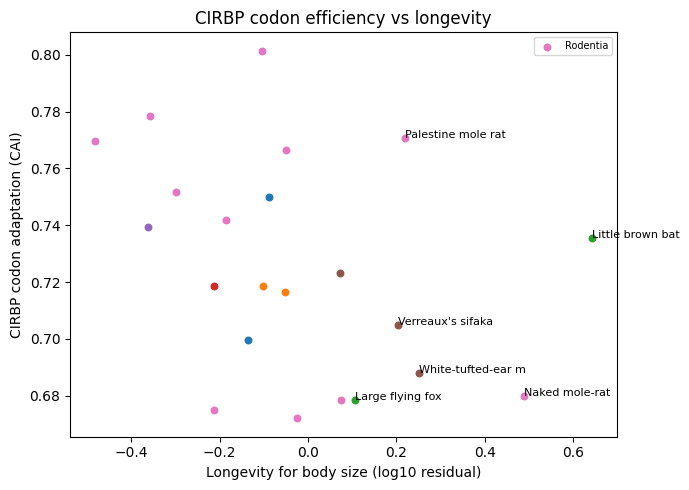

In [6]:
import matplotlib.pyplot as plt
d = M[M.gene == 'CIRBP'].dropna(subset=['cai'])
if len(d):
    plt.figure(figsize=(7, 5))
    for o, dd in d.groupby('Order'): plt.scatter(dd.lon_resid, dd.cai, s=22, label=o if len(dd) > 3 else None)
    for _, r in d.nlargest(6, 'lon_resid').iterrows(): plt.annotate(str(r['Common name'])[:18], (r.lon_resid, r.cai), fontsize=8)
    plt.xlabel('Longevity for body size (log10 residual)'); plt.ylabel('CIRBP codon adaptation (CAI)')
    plt.legend(fontsize=7, ncol=2); plt.title('CIRBP codon efficiency vs longevity'); plt.tight_layout(); plt.show()

## 5. Protein view (test E): which CIRBP positions differ between long- and short-lived species?
1. Translate each CIRBP sequence and line it up against human CIRBP.
2. At every human position, compare amino acids in the **longest-lived quarter** vs **shortest-lived quarter** of species (Fisher test, adjusted for many tests).
3. Score each changed position with **ESM-2**, a protein language model: does the long-lived residue look "more natural" to the model than the short-lived one?
4. Place positions on the **AlphaFold structure** of human CIRBP (RNA-binding RRM domain vs the flexible RGG region).

In [7]:
from Bio.Seq import Seq
from Bio import Align
def translate(s):
    s = s[:len(s) - len(s) % 3]
    try: return str(Seq(s).translate()).rstrip('*')
    except Exception: return ''

prot = {e: translate(s) for e, s in SEQ.get('CIRBP', {}).items()}
REFSP = 'homo_sapiens' if prot.get('homo_sapiens') else min(prot, key=lambda e: abs(len(prot[e]) - np.median([len(x) for x in prot.values()])))
human = prot.get(REFSP, '')
note(f'reference CIRBP protein: {REFSP}, {len(human)} aa (human CIRBP in UniProt Q14011 is 172 aa)')
aligner = Align.PairwiseAligner(); aligner.mode = 'global'
aligner.open_gap_score, aligner.extend_gap_score = -10, -0.5
from Bio.Align import substitution_matrices
aligner.substitution_matrix = substitution_matrices.load('BLOSUM62')

def map_to_human(p):
    aln = aligner.align(human, p)[0]
    col = ['-'] * len(human)
    for (hs, he), (qs, qe) in zip(*aln.aligned):
        for k in range(he - hs): col[hs + k] = p[qs + k]
    return col

d = sp.set_index('ens')
keep = [e for e in prot if e in d.index and len(prot[e]) > 0.7 * len(human)]
A = pd.DataFrame({e: map_to_human(prot[e]) for e in keep}).T   # species x human position
q1, q3 = d.loc[keep, 'lon_resid'].quantile([0.25, 0.75])
longL = [e for e in keep if d.loc[e, 'lon_resid'] >= q3]; shortL = [e for e in keep if d.loc[e, 'lon_resid'] <= q1]
sites = []
for pos in A.columns:
    hum = human[pos]
    a_long = (A.loc[longL, pos] == hum).sum(); b_long = len(longL) - a_long
    a_short = (A.loc[shortL, pos] == hum).sum(); b_short = len(shortL) - a_short
    if b_long + b_short == 0: continue
    odds, p = stats.fisher_exact([[a_long, b_long], [a_short, b_short]])
    alt = A.loc[longL + shortL, pos][lambda x: (x != hum) & (x != '-')].mode()
    sites.append(dict(pos=pos + 1, human=hum, alt=alt.iloc[0] if len(alt) else '-', long_same=a_long / len(longL),
                      short_same=a_short / len(shortL), p=p))
S = pd.DataFrame(sites)
if len(S):
    from statsmodels.stats.multitest import multipletests
    S['fdr'] = multipletests(S.p, method='fdr_bh')[1]
    S = S.sort_values('p')
    note(f'variable CIRBP positions: {len(S)}; positions with FDR<0.1: {(S.fdr < 0.1).sum()}; '
         f'long-lived n={len(longL)}, short-lived n={len(shortL)}')
    note('top positions:\n' + S.head(8).round(3).to_string(index=False))
    S.to_csv('data/cirbp_sites.csv', index=False)

reference CIRBP protein: homo_sapiens, 207 aa (human CIRBP in UniProt Q14011 is 172 aa)
variable CIRBP positions: 90; positions with FDR<0.1: 0; long-lived n=6, short-lived n=6
top positions:
 pos human alt  long_same  short_same     p  fdr
 150     G   S      1.000       0.500 0.182  1.0
 149     G   S      0.500       1.000 0.182  1.0
 181     A   C      0.500       0.000 0.182  1.0
 179     W   N      0.500       0.000 0.182  1.0
 180     P   D      0.500       0.000 0.182  1.0
 192     P   A      0.500       0.000 0.182  1.0
 198     T   M      0.500       0.000 0.182  1.0
 177     L   -      0.667       0.167 0.242  1.0


In [8]:
# ESM-2 score of each top site: log-probability of the residue common in long-lived vs short-lived species
try:
    import torch, esm
    model, alphabet = esm.pretrained.esm2_t12_35M_UR50D(); model.eval(); bc = alphabet.get_batch_converter()
    def site_scores(seq, pos0):
        masked = seq[:pos0] + '<mask>' + seq[pos0 + 1:]
        _, _, toks = bc([('h', masked)])
        with torch.no_grad(): lp = torch.log_softmax(model(toks)['logits'][0, pos0 + 1], -1)
        return {aa: float(lp[alphabet.get_idx(aa)]) for aa in 'ACDEFGHIKLMNPQRSTVWY'}
    out = []
    for _, r in S.head(10).iterrows():
        if r.alt == '-': continue
        sc = site_scores(human, int(r.pos) - 1)
        long_res = r.human if r.long_same >= r.short_same else r.alt
        short_res = r.alt if long_res == r.human else r.human
        out.append(dict(pos=int(r.pos), long_res=long_res, short_res=short_res, esm_logratio=sc[long_res] - sc[short_res]))
    E = pd.DataFrame(out)
    if len(E):
        note('ESM-2: positive log-ratio = the long-lived residue looks more natural to the model\n' + E.round(2).to_string(index=False))
except Exception as e:
    note(f'ESM step skipped: {type(e).__name__}: {e}')

Downloading: "https://dl.fbaipublicfiles.com/fair-esm/models/esm2_t12_35M_UR50D.pt" to /root/.cache/torch/hub/checkpoints/esm2_t12_35M_UR50D.pt
Downloading: "https://dl.fbaipublicfiles.com/fair-esm/regression/esm2_t12_35M_UR50D-contact-regression.pt" to /root/.cache/torch/hub/checkpoints/esm2_t12_35M_UR50D-contact-regression.pt
ESM-2: positive log-ratio = the long-lived residue looks more natural to the model
 pos long_res short_res  esm_logratio
 150        G         S          1.37
 149        S         G         -1.14
 181        A         C          1.09
 179        W         N         -0.74
 180        P         D          1.06
 192        P         A          0.16
 198        T         M          1.44
 172        S         N          1.26
 170        S         T          1.86


In [9]:
# AlphaFold confidence (pLDDT) at the top sites: high = folded RRM domain, low = flexible RGG region
try:
    pdb = requests.get('https://alphafold.ebi.ac.uk/files/AF-Q14011-F1-model_v4.pdb', timeout=60).text
    pl = {}
    for line in pdb.splitlines():
        if line.startswith('ATOM') and line[12:16].strip() == 'CA': pl[int(line[22:26])] = float(line[60:66])
    if pl and len(S):
        S['alphafold_plddt'] = S.pos.map(pl)
        S['region'] = np.where(S.pos <= 90, 'RRM (RNA-binding)', 'RGG / C-terminal')
        note('AlphaFold confidence at top sites:\n' + S.head(8)[['pos', 'human', 'alt', 'p', 'alphafold_plddt', 'region']].round(3).to_string(index=False))
except Exception as e:
    note(f'AlphaFold step skipped: {type(e).__name__}: {e}')

## How to read the result
- **Supports the idea:** CIRBP CAI rises with longevity (positive rho, order-corrected p < 0.05) **and** beats most control genes (above about 90%).
- **Arg CGN share falling with longevity** would match the "avoid mutation-prone codons" story, but that trend exists genome-wide, so CIRBP must beat the controls to count.
- **No signal** is a real answer too: then the bowhead's CIRBP is a whale-specific trick, not a mammal-wide rule.

In [10]:
print('=' * 70); print('SEND THIS TO CLAUDE'); print('=' * 70); print('\n'.join(REPORT)); print('=' * 70)

SEND THIS TO CLAUDE
genes: 2 target, 22 reference, 45 control
downloaded 39 genes; skipped: ['HNRNPA1', 'G3BP1']
CIRBP length: median 173 aa (range 167-217); human 207; long isoforms trimmed to core: 18; still dropped: 22
species per gene: CIRBP=56, RBM3=51; ref genes median species=66
AnAge mammals: 1349
filled from same genus (1): catagonus_wagneri
Ensembl species still with no AnAge lifespan (5): catagonus_wagneri, mus_caroli, mus_pahari, mus_spretus, rhinopithecus_bieti
species with CIRBP + lifespan: 23; orders: 7; with body temperature: 23
species used (longevity residual): Golden hamster -0.48, Gray short-tailed opossum -0.36, House mouse -0.36, Prairie vole -0.30, Thirteen-lined ground squirrel -0.21, Tasmanian devil -0.21, Lesser Egyptian jerboa -0.19, Dromedary -0.14, Guinea pig -0.10, Tiger -0.10, Wild boar -0.09, Lion -0.05, Deer mouse -0.05, Ord's kangaroo rat -0.03, Small-eared galago +0.07, Long-tailed chinchilla +0.08, Large flying fox +0.11, Verreaux's sifaka +0.20, Pal